In [1]:

%load_ext autoreload
%autoreload 2

from pl_trainer import LightningModule
from data_module import MNISTDataModule
from torchvision import transforms
import torch.nn as nn
import lightning.pytorch as pl
import pandas as pd
import matplotlib.pyplot as plt
import torch

pl.seed_everything(42)

Seed set to 42


42

# Setting up Hyperparameters

In [7]:
lr = 0.001 # Change learning rate here
batch_size = 64
max_epochs = 5

# Setting up Optimizer

In [8]:
optimizer = torch.optim.Adam # Change the optimizer here

# Defining Model Architecture 

In [9]:
def create_model():
    """
        Initializes the model. Edit the code below if you would like to change the model.
    """
    # Replace this placeholder network.
    model = nn.Sequential(
        nn.Conv2d(1, 32, 5, stride=1, padding=2),
        nn.MaxPool2d(2, stride=2),
        nn.Conv2d(32, 64, 3, stride=1, padding=1),
        nn.MaxPool2d(2, stride=2),
        nn.Conv2d(64, 128, 3, stride=1, padding=1),
        nn.MaxPool2d(2, stride=2),
        nn.Flatten(),
        nn.Linear(4*4*128, 64),
        nn.Linear(64, 10), 
    )
    
    return model

# Initialize the model, data module, and trainer
pl_model = LightningModule(model=create_model(), lr=lr, optimizer=optimizer)

# Setting up Dataloaders and Transformations

In [10]:
my_transforms = transforms.Compose([
        transforms.Resize((32, 32)),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])])


mnist_data = MNISTDataModule(batch_size=batch_size, transforms=my_transforms)

# Train Model

In [11]:
# Initialize CSVLogger
csv_logger = pl.loggers.CSVLogger(save_dir='logs/', name='mnist_logs', version=0)

# Set up the trainer
trainer = pl.Trainer(max_epochs=max_epochs, 
                     logger=csv_logger, 
                     check_val_every_n_epoch=1, 
                     enable_checkpointing=False,
                     deterministic=True)

# Train the model
trainer.fit(pl_model, mnist_data)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/clem/Bureau/Visual_Computing_Fundamentals/Part2_Image_Processing/Assignments/TDT4195-StarterCode-2025/.venv/lib/python3.10/site-packages/lightning/fabric/loggers/csv_logs.py:268: Experiment logs directory logs/mnist_logs/version_0 exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!

  | Name    | Type               | Params | Mode  | FLOPs
---------------------------------------------------------------
0 | model   | Sequential         | 224 K  | train | 0    
1 | loss_fn | CrossEntropyLoss   | 0      | train | 0    
2 | acc_fn  | MulticlassAccuracy | 0      | train | 0    
------------------------------------------------------

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

/home/clem/Bureau/Visual_Computing_Fundamentals/Part2_Image_Processing/Assignments/TDT4195-StarterCode-2025/.venv/lib/python3.10/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/clem/Bureau/Visual_Computing_Fundamentals/Part2_Image_Processing/Assignments/TDT4195-StarterCode-2025/.venv/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


/home/clem/Bureau/Visual_Computing_Fundamentals/Part2_Image_Processing/Assignments/TDT4195-StarterCode-2025/.venv/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Epoch 4: 100%|██████████| 937/937 [01:08<00:00, 13.74it/s, v_num=0, val_acc=0.986, val_loss=0.0421]

`Trainer.fit` stopped: `max_epochs=5` reached.


Epoch 4: 100%|██████████| 937/937 [01:08<00:00, 13.73it/s, v_num=0, val_acc=0.986, val_loss=0.0421]


# Plot Results

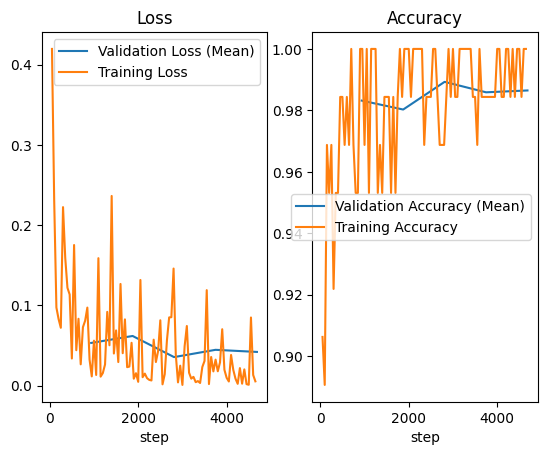

Final validation loss 0.0421
Final validation accuracy 0.9865


In [12]:
df = pd.read_csv('logs/mnist_logs/version_0/metrics.csv')

# Create a figure and axes objects
fig, ax = plt.subplots(1,2)

# Plot 'val_loss' on the axes
df.dropna(subset=['val_loss']).plot(x='step', y='val_loss', ax=ax[0], label='Validation Loss (Mean)')
# Plot 'train_loss' on the same axes
df.dropna(subset=['train_loss']).plot(x='step', y='train_loss', ax=ax[0], label='Training Loss')

# Plot 'val_loss' on the axes
df.dropna(subset=['val_acc']).plot(x='step', y='val_acc', ax=ax[1], label='Validation Accuracy (Mean)')
# Plot 'train_loss' on the same axes
df.dropna(subset=['train_acc']).plot(x='step', y='train_acc', ax=ax[1], label='Training Accuracy')

ax[0].set_title('Loss')
ax[1].set_title('Accuracy')
plt.show()

print("Final validation loss", round(df['val_loss'].iloc[-1], 4))
print("Final validation accuracy", round(df['val_acc'].iloc[-1], 4))